In [51]:
import pandas as pd
import statsmodels.api as sm

In [52]:
df = pd.read_csv("data/final.csv")

In [53]:
df

,Unnamed: 0.1,Unnamed: 0,log_ret,monthly_return,IV,RV,VRP,log_PE,log_PD,CAY,...,GS10,TB3MS,DFSP,TMSP,RREL,excess_ret,cay_imputed,VIX3M,VIX_Regime_Medium,VIX_Regime_High
0,0,2008-03-31,-0.014079,-0.025783,0.065171,0.058995,0.006176,3.079178,3.875335,0.006081,...,3.74,2.12,1.29,1.62,-1.805000,-0.027531,0.006081,25.394500,False,True
1,1,2008-04-30,0.048108,-0.013980,0.073852,0.075129,-0.001277,3.082243,3.840204,0.009843,...,3.51,1.26,1.38,2.25,-2.358333,-0.015024,0.009843,26.888000,False,True
2,2,2008-05-31,0.013493,0.049283,0.046684,0.046326,0.000358,3.173155,3.875230,0.009843,...,3.68,1.29,1.42,2.39,-2.030000,0.048215,0.009843,22.488636,True,False
3,3,2008-06-30,-0.091226,0.013585,0.033596,0.037002,-0.003406,3.250590,3.894051,0.009843,...,3.88,1.73,1.36,2.15,-1.340000,0.012155,0.009843,20.617619,True,False
4,4,2008-07-31,-0.009495,-0.087189,0.049107,0.050400,-0.001293,3.262303,3.844112,-0.006757,...,4.10,1.86,1.39,2.24,-0.980833,-0.088725,-0.006757,23.129524,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,154,2021-01-31,-0.013283,0.027612,0.050212,0.031184,0.019028,3.670143,4.149581,-0.043572,...,0.93,0.09,0.90,0.84,-0.275000,0.027537,-0.043572,25.429091,False,True
155,155,2021-02-28,0.028761,-0.013195,0.063758,0.040120,0.023637,3.582525,4.179569,-0.043469,...,1.08,0.08,0.79,1.00,-0.165000,-0.013261,-0.043469,27.552632,False,True
156,156,2021-03-31,0.041269,0.029179,0.054342,0.037756,0.016587,3.503641,4.206646,-0.043030,...,1.26,0.04,0.72,1.22,-0.081667,0.029145,-0.043030,27.811579,False,True
157,157,2021-04-30,0.051760,0.042132,0.048388,0.050433,-0.002045,3.417831,4.217321,-0.042450,...,1.61,0.03,0.70,1.58,-0.070000,0.042107,-0.042450,25.341739,False,True


In [54]:
df["VRP_sq"] = df["VRP"]**2
df["IV_sq"] = df["IV"]**2
df["VRP_IV"] = df["VRP"] * df["IV"]

In [55]:
df["slope"] = df["VIX3M"] - df["IV"]
df["slope_sq"] = df["slope"]**2
df["VRP_slope"] = df["VRP"] * df["slope"]

In [56]:
df["VRP_3M"] = df["VIX3M"] - df["RV"]
df["vol_ratio"] = df["VIX3M"] / df["IV"]

In [57]:
df_reg = df.copy()
df_reg["excess_ret_lead"] = df_reg["excess_ret"].shift(-1)

In [58]:
df_reg = df_reg[df_reg["VRP"] != df_reg["VRP"].min()]
df_reg = df_reg[df_reg["VRP"] != df_reg["VRP"].max()]

## Replication of the Paper

### Simple Linear Regression

In [59]:
reg_data = df_reg[["excess_ret_lead", "VRP"]].dropna()

X = sm.add_constant(reg_data["VRP"])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                    0.4623
Date:                Wed, 08 Apr 2026   Prob (F-statistic):              0.498
Time:                        01:33:05   Log-Likelihood:                 259.76
No. Observations:                 156   AIC:                            -515.5
Df Residuals:                     154   BIC:                            -509.4
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0075      0.004      2.083      0.0

In [151]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Parameter
initial_window = 120
maxlags = 6

data = df_reg[["excess_ret_lead", "VRP"]].dropna().reset_index(drop=True)

y_true = []
y_pred = []

for t in range(initial_window, len(data)):

    train = data.iloc[:t]
    test = data.iloc[t:t+1]

    # --- Train ---
    X_train = sm.add_constant(train[["VRP"]], has_constant="add")
    y_train = train["excess_ret_lead"]

    model = sm.OLS(y_train, X_train).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags}
    )

    # --- Test ---
    X_test = sm.add_constant(test[["VRP"]], has_constant="add")
    pred = model.predict(X_test).iloc[0]

    y_pred.append(pred)
    y_true.append(test["excess_ret_lead"].values[0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [152]:
y_bar = np.mean(y_true)

r2_oos = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_bar)**2)

print("OOS R^2:", r2_oos)

OOS R^2: 0.007552405760060998


### Linear Regression with more Controls

In [60]:
controls = ["log_PE", "DFSP", "TMSP", "CAY", "log_PD", "RREL"]

reg_data = df_reg[["excess_ret_lead", "VRP"] + controls].dropna()

X = sm.add_constant(reg_data[["VRP"] + controls])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.105
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     2.077
Date:                Wed, 08 Apr 2026   Prob (F-statistic):             0.0495
Time:                        01:33:05   Log-Likelihood:                 267.22
No. Observations:                 156   AIC:                            -518.4
Df Residuals:                     148   BIC:                            -494.0
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6567      0.293      2.241      0.0

### Linear Regression Higher Lag

In [61]:
k = 6

df_reg[f"ret_{k}m"] = df_reg["excess_ret"].rolling(k).sum().shift(-k)

reg_data = df_reg[[f"ret_{k}m", "VRP"]].dropna()

X = sm.add_constant(reg_data["VRP"])
y = reg_data[f"ret_{k}m"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": k})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 ret_6m   R-squared:                       0.118
Model:                            OLS   Adj. R-squared:                  0.112
Method:                 Least Squares   F-statistic:                     13.98
Date:                Wed, 08 Apr 2026   Prob (F-statistic):           0.000262
Time:                        01:33:05   Log-Likelihood:                 124.67
No. Observations:                 151   AIC:                            -245.3
Df Residuals:                     149   BIC:                            -239.3
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0472      0.017      2.738      0.0

## Polynomial Regression

In [63]:
df_reg["VRP_sq"] = df_reg["VRP"]**2

reg_data = df_reg[["excess_ret_lead", "VRP", "VRP_sq"]].dropna()

X = sm.add_constant(reg_data[["VRP", "VRP_sq"]])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.127
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     7.863
Date:                Wed, 08 Apr 2026   Prob (F-statistic):           0.000562
Time:                        01:33:05   Log-Likelihood:                 269.16
No. Observations:                 156   AIC:                            -532.3
Df Residuals:                     153   BIC:                            -523.2
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0125      0.003      4.403      0.0

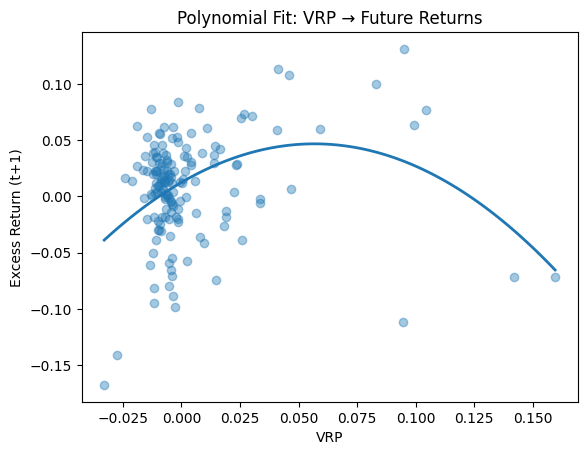

In [64]:
import numpy as np
import matplotlib.pyplot as plt

# Scatter (Daten)
plt.scatter(reg_data["VRP"], y, alpha=0.4)

# Grid für glatte Kurve
vrp_grid = np.linspace(reg_data["VRP"].min(), reg_data["VRP"].max(), 100)

X_grid = sm.add_constant(
    np.column_stack([vrp_grid, vrp_grid**2])
)

y_pred = model.predict(X_grid)

# Fit-Linie
plt.plot(vrp_grid, y_pred, linewidth=2)

plt.xlabel("VRP")
plt.ylabel("Excess Return (t+1)")
plt.title("Polynomial Fit: VRP → Future Returns")
plt.show()

In [154]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Sicherstellen, dass Feature existiert
df_reg["VRP_sq"] = df_reg["VRP"]**2

# Parameter
initial_window = 120
maxlags = 6

data = df_reg[["excess_ret_lead", "VRP", "VRP_sq"]].dropna().reset_index(drop=True)

y_true = []
y_pred = []

for t in range(initial_window, len(data)):

    train = data.iloc[:t]
    test = data.iloc[t:t+1]

    # --- Train ---
    X_train = sm.add_constant(train[["VRP", "VRP_sq"]], has_constant="add")
    y_train = train["excess_ret_lead"]

    model = sm.OLS(y_train, X_train).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags}
    )

    # --- Test ---
    X_test = sm.add_constant(test[["VRP", "VRP_sq"]], has_constant="add")
    pred = model.predict(X_test).iloc[0]

    y_pred.append(pred)
    y_true.append(test["excess_ret_lead"].values[0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [155]:
y_bar = np.mean(y_true)

r2_oos = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_bar)**2)

print("OOS R^2:", r2_oos)

OOS R^2: 0.08635042103040469


## Splines

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.253
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     54.86
Date:                Wed, 08 Apr 2026   Prob (F-statistic):           2.61e-35
Time:                        03:08:11   Log-Likelihood:                 281.31
No. Observations:                 156   AIC:                            -548.6
Df Residuals:                     149   BIC:                            -527.3
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                                                                coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------

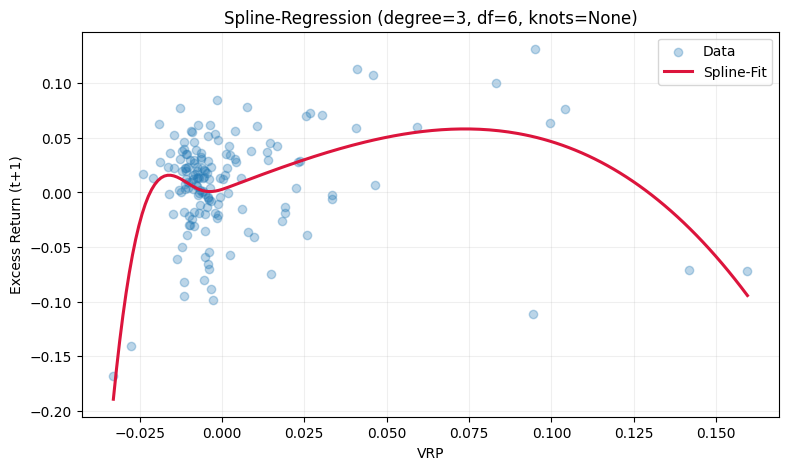

In [156]:
from patsy import dmatrix, build_design_matrices
from patsy.builtins import bs as patsy_bs

spline_df = 6             # degrees of freedom 
spline_degree = 3         # degree of splines
knots = None               

# Daten
spline_data = df_reg[["VRP", "excess_ret_lead"]].dropna()
y_spline = spline_data["excess_ret_lead"]

if knots is None:
    spline_formula = f"patsy_bs(VRP, df={spline_df}, degree={spline_degree}, include_intercept=False)"
else:
    knots = sorted(knots)
    knot_str = ", ".join(map(str, knots))
    spline_formula = f"patsy_bs(VRP, knots=({knot_str}), degree={spline_degree}, include_intercept=False)"

X_spline = dmatrix(
    spline_formula,
    data=spline_data,
    return_type="dataframe",
    eval_env=0
)

spline_model = sm.OLS(y_spline, X_spline).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(spline_model.summary())

vrp_grid_spline = np.linspace(spline_data["VRP"].min(), spline_data["VRP"].max(), 200)
grid_df = pd.DataFrame({"VRP": vrp_grid_spline})
X_grid_spline = build_design_matrices([X_spline.design_info], grid_df)[0]
y_spline_pred = spline_model.predict(X_grid_spline)

plt.figure(figsize=(9, 5))
plt.scatter(spline_data["VRP"], spline_data["excess_ret_lead"], alpha=0.3, label="Data")
plt.plot(vrp_grid_spline, y_spline_pred, color="crimson", linewidth=2.2, label="Spline-Fit")
plt.xlabel("VRP")
plt.ylabel("Excess Return (t+1)")
plt.title(f"Spline-Regression (degree={spline_degree}, df={spline_df}, knots={knots})")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [68]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrix, build_design_matrices

# Parameter
initial_window = 132
maxlags = 6

# Daten vorbereiten
data = df_reg[["VRP", "excess_ret_lead"]].dropna().reset_index(drop=True)

y_true = []
y_pred = []

for t in range(initial_window, len(data)):

    train = data.iloc[:t]
    test = data.iloc[t:t+1]

    # --- Design Matrix TRAIN ---
    X_train = dmatrix(
        spline_formula,
        data=train,
        return_type="dataframe"
    )

    y_train = train["excess_ret_lead"]

    model = sm.OLS(y_train, X_train).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags}
    )

    # --- Design Matrix TEST ---
    X_test = build_design_matrices(
        [X_train.design_info],
        test
    )[0]

    pred = model.predict(X_test)[0]

    y_pred.append(pred)
    y_true.append(test["excess_ret_lead"].values[0])

In [69]:
y_true = np.array(y_true)
y_pred = np.array(y_pred)

mse = np.mean((y_true - y_pred)**2)
rmse = np.sqrt(mse)

print("OOS RMSE:", rmse)

OOS RMSE: 0.05064287265495374


In [70]:
y_bar = np.mean(y_true)

r2_oos = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_bar)**2)

print("OOS R^2:", r2_oos)

OOS R^2: 0.2560618281957795


In [71]:
direction_acc = np.mean(np.sign(y_pred) == np.sign(y_true))
print("Directional Accuracy:", direction_acc)

Directional Accuracy: 0.7083333333333334


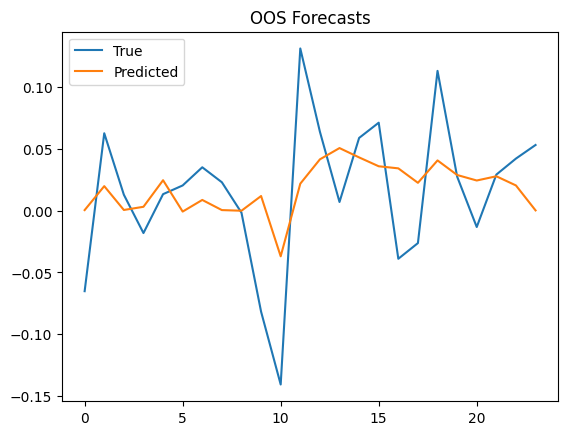

In [72]:
import matplotlib.pyplot as plt

plt.plot(y_true, label="True")
plt.plot(y_pred, label="Predicted")
plt.legend()
plt.title("OOS Forecasts")
plt.show()

In [143]:
from patsy import dmatrix, build_design_matrices
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt

# Daten vorbereiten
spline_data = df_reg[["VRP", "excess_ret_lead", 
                      "VIX_Regime_Medium", "VIX_Regime_High"]].dropna().copy()

y = spline_data["excess_ret_lead"]

# --- Basisspline (Low-Regime ist Referenz) ---
X_base = dmatrix(
    "patsy_bs(VRP, df=4, degree=3, include_intercept=False)",
    data=spline_data,
    return_type="dataframe"
)

# --- Interaktionen mit Regimen ---
X_medium = X_base.multiply(spline_data["VIX_Regime_Medium"], axis=0)
X_high   = X_base.multiply(spline_data["VIX_Regime_High"], axis=0)

# Spalten sauber benennen
X_medium.columns = [col + "_med" for col in X_base.columns]
X_high.columns   = [col + "_high" for col in X_base.columns]

# Finales Design
X_full = pd.concat([X_base, X_medium, X_high], axis=1)
X_full = sm.add_constant(X_full)

# Regression
model = sm.OLS(y, X_full).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.332
Model:                            OLS   Adj. R-squared:                  0.265
Method:                 Least Squares   F-statistic:                     541.7
Date:                Wed, 08 Apr 2026   Prob (F-statistic):          5.45e-115
Time:                        01:51:20   Log-Likelihood:                 290.02
No. Observations:                 156   AIC:                            -550.0
Df Residuals:                     141   BIC:                            -504.3
Df Model:                          14                                         
Covariance Type:                  HAC                                         
                                                                     coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

OOS RMSE: 0.05329235921145864
OOS R^2: 0.1761842870588498


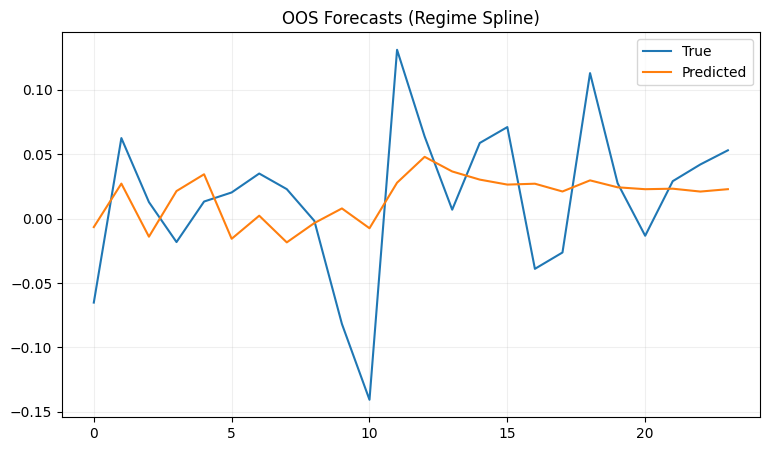

In [144]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrix, build_design_matrices

# Parameter
initial_window = 132
maxlags = 6

# Daten (inkl. Regime!)
data = df_reg[[
    "VRP", "excess_ret_lead",
    "VIX_Regime_Medium", "VIX_Regime_High"
]].dropna().reset_index(drop=True)

y_true = []
y_pred = []

for t in range(initial_window, len(data)):

    train = data.iloc[:t].copy()
    test  = data.iloc[t:t+1].copy()

    # -----------------------------
    # TRAIN DESIGN MATRIX
    # -----------------------------
    X_base_train = dmatrix(
        "patsy_bs(VRP, df=4, degree=3, include_intercept=False)",
        data=train,
        return_type="dataframe"
    )

    # Interaktionen
    X_med_train  = X_base_train.multiply(train["VIX_Regime_Medium"], axis=0)
    X_high_train = X_base_train.multiply(train["VIX_Regime_High"], axis=0)

    X_med_train.columns  = [c + "_med" for c in X_base_train.columns]
    X_high_train.columns = [c + "_high" for c in X_base_train.columns]

    X_train = pd.concat([X_base_train, X_med_train, X_high_train], axis=1)
    X_train = sm.add_constant(X_train)

    y_train = train["excess_ret_lead"]

    model = sm.OLS(y_train, X_train).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags}
    )

    # -----------------------------
    # TEST DESIGN MATRIX
    # -----------------------------
    X_base_test = build_design_matrices(
        [X_base_train.design_info],
        test
    )[0]
    X_base_test = pd.DataFrame(X_base_test, columns=X_base_train.columns)

    # Interaktionen TEST
    X_med_test  = X_base_test.multiply(test["VIX_Regime_Medium"].values[0])
    X_high_test = X_base_test.multiply(test["VIX_Regime_High"].values[0])

    X_med_test.columns  = [c + "_med" for c in X_base_test.columns]
    X_high_test.columns = [c + "_high" for c in X_base_test.columns]

    X_test = pd.concat([X_base_test, X_med_test, X_high_test], axis=1)
    X_test = sm.add_constant(X_test)

    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # Prediction
    pred = model.predict(X_test)[0]

    y_pred.append(pred)
    y_true.append(test["excess_ret_lead"].values[0])

# Arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Metrics
mse = np.mean((y_true - y_pred)**2)
rmse = np.sqrt(mse)

print("OOS RMSE:", rmse)

y_bar = np.mean(y_true)
r2_oos = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_bar)**2)

print("OOS R^2:", r2_oos)

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))
plt.plot(y_true, label="True")
plt.plot(y_pred, label="Predicted")
plt.legend()
plt.title("OOS Forecasts (Regime Spline)")
plt.grid(alpha=0.2)
plt.show()